<h2 style="border:1px solid #EA580C; padding:20px; margin:0; color:#EA580C"><center> Blood Donation Prediction </center></h2>

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("blood_donation_data.csv")
df.head()

,Months since Last Donation,Number of Donations,Total Volume Donated (c.c.),Months since First Donation,Made Donation in March 2007
0,6,5,1250,8,0
1,10,1,250,15,0
2,3,3,750,43,1
3,3,10,2500,82,1
4,4,18,4500,33,1


<h3 style="color:#0F766E; border: 1px solid #0F766E; padding:5px; text-align:center">EDA & Data Processing</h3>

In [3]:
df.head()

,Months since Last Donation,Number of Donations,Total Volume Donated (c.c.),Months since First Donation,Made Donation in March 2007
0,6,5,1250,8,0
1,10,1,250,15,0
2,3,3,750,43,1
3,3,10,2500,82,1
4,4,18,4500,33,1


In [4]:
df.tail()

,Months since Last Donation,Number of Donations,Total Volume Donated (c.c.),Months since First Donation,Made Donation in March 2007
20395,26,4,1000,66,0
20396,2,3,750,19,1
20397,11,4,1000,35,0
20398,5,4,1000,15,1
20399,17,3,750,33,0


In [5]:
df.sample(5)

,Months since Last Donation,Number of Donations,Total Volume Donated (c.c.),Months since First Donation,Made Donation in March 2007
7080,13,2,500,38,0
8337,4,4,1000,21,1
11716,27,5,1250,37,0
15621,14,2,500,34,1
7950,28,9,2250,28,0


In [6]:
df.columns.tolist()

['Months since Last Donation',
 'Number of Donations',
 'Total Volume Donated (c.c.)',
 'Months since First Donation',
 'Made Donation in March 2007']

In [7]:
df.ndim

2

In [8]:
df.dtypes

Months since Last Donation     int64
Number of Donations            int64
Total Volume Donated (c.c.)    int64
Months since First Donation    int64
Made Donation in March 2007    int64
dtype: object

In [9]:
# df.drop("Unnamed: 0",axis=1, inplace=True)
df.describe()

,Months since Last Donation,Number of Donations,Total Volume Donated (c.c.),Months since First Donation,Made Donation in March 2007
count,20400.000000,20400.000000,20400.000000,20400.000000,20400.00000
mean,8.349020,4.249069,1062.267157,36.485343,0.40000
std,6.700848,3.097477,774.369360,19.667085,0.48991
min,0.000000,1.000000,250.000000,3.000000,0.00000
25%,4.000000,2.000000,500.000000,22.000000,0.00000
50%,7.000000,3.000000,750.000000,32.000000,0.00000
75%,11.000000,6.000000,1500.000000,47.000000,1.00000
max,67.000000,32.000000,8000.000000,98.000000,1.00000


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20400 entries, 0 to 20399
Data columns (total 5 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Months since Last Donation   20400 non-null  int64
 1   Number of Donations          20400 non-null  int64
 2   Total Volume Donated (c.c.)  20400 non-null  int64
 3   Months since First Donation  20400 non-null  int64
 4   Made Donation in March 2007  20400 non-null  int64
dtypes: int64(5)
memory usage: 797.0 KB


In [11]:
df.isnull().sum()

Months since Last Donation     0
Number of Donations            0
Total Volume Donated (c.c.)    0
Months since First Donation    0
Made Donation in March 2007    0
dtype: int64

In [12]:
df.shape

(20400, 5)

In [13]:
data = pd.read_csv("Warm_Up_Predict_Blood_Donations_-_Traning_Data.csv")
data.duplicated().sum()

np.int64(0)

In [14]:
# Correlation of the dependent feature with other features
for i in df.columns:
    print(f"Correlation of Dependent feature and {i}  : { df[i].corr(df['Made Donation in March 2007']) }")

Correlation of Dependent feature and Months since Last Donation  : -0.37521977255471145
Correlation of Dependent feature and Number of Donations  : 0.4240518435716966
Correlation of Dependent feature and Total Volume Donated (c.c.)  : 0.4240518435716963
Correlation of Dependent feature and Months since First Donation  : 0.013521487618840268
Correlation of Dependent feature and Made Donation in March 2007  : 1.0


In [15]:
# Correlation between the columns
df.drop(["Made Donation in March 2007"],axis=1).corr()

,Months since Last Donation,Number of Donations,Total Volume Donated (c.c.),Months since First Donation
Months since Last Donation,1.000000,-0.163869,-0.163869,0.043478
Number of Donations,-0.163869,1.000000,1.000000,0.005048
Total Volume Donated (c.c.),-0.163869,1.000000,1.000000,0.005048
Months since First Donation,0.043478,0.005048,0.005048,1.000000


<h3 style="color:#0F766E; border: 1px solid #0F766E; padding:5px; text-align:center">Comparing mean of No Donated VS Donated </h3>


In [16]:
df.groupby("Made Donation in March 2007").mean().rename(
    index={0: "No Donation", 1: "Donated"}
).T

Made Donation in March 2007,No Donation,Donated
Months since Last Donation,10.401879,5.269730
Number of Donations,3.176634,5.857721
Total Volume Donated (c.c.),794.158497,1464.430147
Months since First Donation,36.268219,36.811029


In [17]:
for i in df.columns:
    print(i +": ", df[i].nunique())
    
# Unique values in each feature

Months since Last Donation:  56
Number of Donations:  26
Total Volume Donated (c.c.):  26
Months since First Donation:  96
Made Donation in March 2007:  2


In [18]:
df[df["Months since Last Donation"]  >5]["Made Donation in March 2007"].value_counts()

# Most people who have not donated blood in the last 5 months are less likely to donate again in march 2007.

Made Donation in March 2007
0    8730
1    3128
Name: count, dtype: int64

In [19]:
df.groupby("Made Donation in March 2007").mean()["Total Volume Donated (c.c.)"].rename(
    index={0: "NO Donation", 1: "Donated"}
)

# People who donated blood in March 2007 had a higher average
# total blood donation volume (1920 cc) than those who did not (1179 cc).

Made Donation in March 2007
NO Donation     794.158497
Donated        1464.430147
Name: Total Volume Donated (c.c.), dtype: float64

In [20]:
df.columns

Index(['Months since Last Donation', 'Number of Donations',
       'Total Volume Donated (c.c.)', 'Months since First Donation',
       'Made Donation in March 2007'],
      dtype='object')

In [21]:
df[df["Number of Donations"] == 1].shape

# 118 people have only donated once

(3229, 5)

In [22]:
df[df["Number of Donations"] > 20].shape

# 11 People have donated blood more than 20 times

(26, 5)

In [23]:
df[df["Months since Last Donation"] < 12].shape

# There are around 374 new donors

(15536, 5)

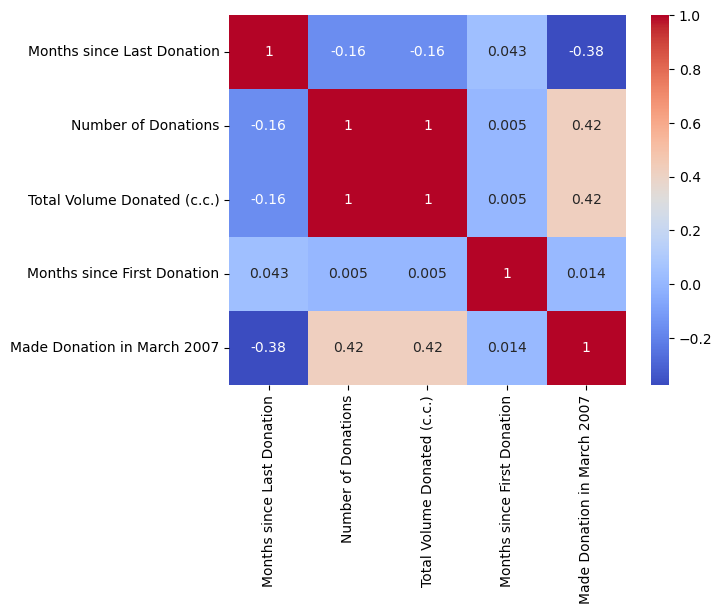

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df.corr()

sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

In [25]:
df.columns.tolist()

['Months since Last Donation',
 'Number of Donations',
 'Total Volume Donated (c.c.)',
 'Months since First Donation',
 'Made Donation in March 2007']

In [26]:
print("Mean: \n")
for i in df.drop(["Made Donation in March 2007"],axis=1).columns:
    print(f"{i}: {df[i].mean()}")

Mean: 

Months since Last Donation: 8.349019607843138
Number of Donations: 4.24906862745098
Total Volume Donated (c.c.): 1062.2671568627452
Months since First Donation: 36.4853431372549


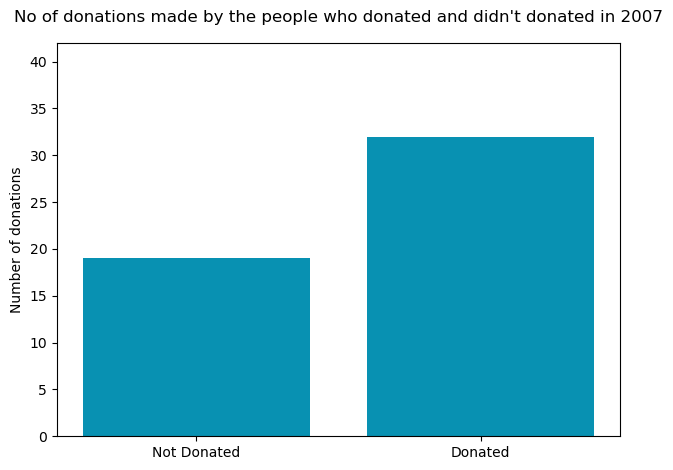

In [27]:
plt.bar(df["Made Donation in March 2007"], df["Number of Donations"], color='#0891B2')
plt.style.use("default")
plt.xticks([0,1],["Not Donated", "Donated"])
plt.title("No of donations made by the people who donated and didn't donated in 2007".capitalize(),pad=15)
plt.ylabel("Number of donations")
plt.ylim(0, max(df["Number of Donations"])+10)
plt.tight_layout()
plt.show()

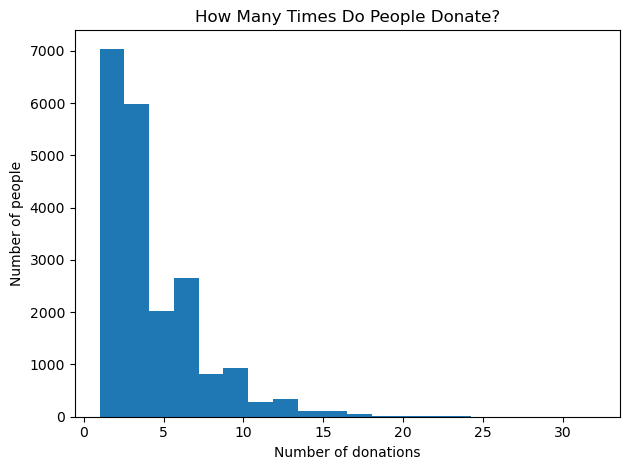

In [28]:
df["Number of Donations"].plot(kind="hist", bins=20)

plt.title("How Many Times Do People Donate?")
plt.xlabel("Number of donations")
plt.ylabel("Number of people")
plt.tight_layout()
plt.show()

<h3 style="color:#0F766E; border: 1px solid #0F766E; padding:4px; text-align:center">Checking Imbalance data</h3>

In [29]:
print(f"\n 0: {df[df["Made Donation in March 2007"] == 1]["Made Donation in March 2007"].count()}")
print(f" 1: {df[df["Made Donation in March 2007"] == 0]["Made Donation in March 2007"].count()}\n")
print("Data is imbalance")


 0: 8160
 1: 12240

Data is imbalance


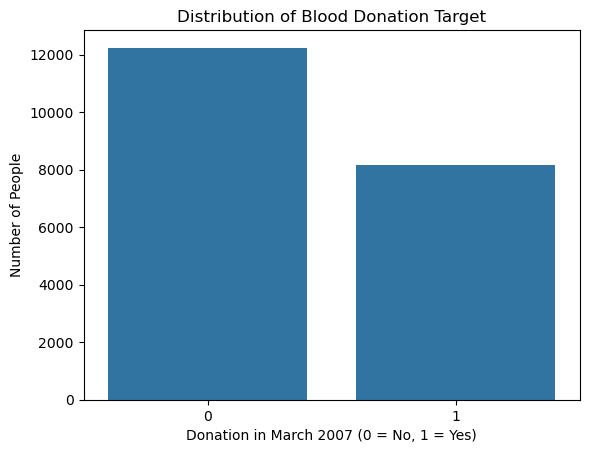

In [30]:
target = "Made Donation in March 2007"

sns.countplot(data=df, x=target)
plt.title("Distribution of Blood Donation Target")
plt.xlabel("Donation in March 2007 (0 = No, 1 = Yes)")
plt.ylabel("Number of People")
plt.show()

In [31]:
X = df.drop(["Made Donation in March 2007"],axis=1)
y = df["Made Donation in March 2007"]

y.head()
X.head()

,Months since Last Donation,Number of Donations,Total Volume Donated (c.c.),Months since First Donation
0,6,5,1250,8
1,10,1,250,15
2,3,3,750,43
3,3,10,2500,82
4,4,18,4500,33


<h3 style="color:#0F766E; border: 1px solid #0F766E; padding:5px; text-align:center">Train Test Split </h3>


In [32]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=40)

X_test.head(2)

,Months since Last Donation,Number of Donations,Total Volume Donated (c.c.),Months since First Donation
11145,6,3,750,13
18481,6,5,1250,22


<h3 style="color:#0F766E; border: 1px solid #0F766E; padding:4px; text-align:center">Feature Sandardization</h3>

In [33]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train = pd.DataFrame(  X_train_scaled, columns=X_train.columns)
X_test = pd.DataFrame(  X_test_scaled, columns=X_test.columns)

X_train.head(2)

,Months since Last Donation,Number of Donations,Total Volume Donated (c.c.),Months since First Donation
0,-0.347434,-0.083736,-0.083736,0.277056
1,-0.497314,-0.725926,-0.725926,-0.282372


<h3 style="color:#0F766E; border: 1px solid #0F766E; padding:4px; text-align:center">Applying SMOTE</h3>

In [34]:
from imblearn.over_sampling import SMOTE

smote = SMOTE()
X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train, y_train
)

In [35]:
print("\n Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_resampled.value_counts())


 Before SMOTE:
Made Donation in March 2007
0    9776
1    6544
Name: count, dtype: int64

After SMOTE:
Made Donation in March 2007
1    9776
0    9776
Name: count, dtype: int64


<h3 style="color:#0F766E; border: 1px solid #0F766E; padding:5px; text-align:center">Model Building </h3>


<h3 style="color:#0F766E; border: 1px solid #0F766E; padding:4px; text-align:center">Logistic Regression</h3>

In [36]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression( max_iter=500, random_state= 40)
lr_model.fit(X_train_resampled, y_train_resampled)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,40
,solver,'lbfgs'
,max_iter,500
,multi_class,'deprecated'


In [37]:
from sklearn.metrics import classification_report

y_pred_lr = lr_model.predict(X_test)
print(classification_report(y_test,y_pred_lr))

              precision    recall  f1-score   support

           0       0.81      0.75      0.78      2464
           1       0.66      0.74      0.69      1616

    accuracy                           0.74      4080
   macro avg       0.73      0.74      0.74      4080
weighted avg       0.75      0.74      0.75      4080



In [38]:
from sklearn.metrics import confusion_matrix

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Confusion Matrix:
[[1839  625]
 [ 423 1193]]


<h3 style="color:#0F766E; border: 1px solid #0F766E; padding:5px; text-align:center">Naive Bayes </h3>

In [39]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
# The reason I'm not using the SMOTE dataset is that I'm getting an error 

,priors,None
,var_smoothing,1e-09


In [40]:
from sklearn.metrics import classification_report

y_pred_nb = nb_model.predict(X_test)
print(classification_report(y_test,y_pred_nb))

              precision    recall  f1-score   support

           0       0.73      0.87      0.80      2464
           1       0.73      0.51      0.60      1616

    accuracy                           0.73      4080
   macro avg       0.73      0.69      0.70      4080
weighted avg       0.73      0.73      0.72      4080



In [41]:
from sklearn.metrics import confusion_matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))

Confusion Matrix:
[[2154  310]
 [ 791  825]]


<h3 style="color:#0F766E; border: 1px solid #0F766E; padding:5px; text-align:center">SVM</h3>

In [42]:
from sklearn.svm import SVC

svm_model = SVC( kernel="rbf", C=10,random_state=40)
svm_model.fit(X_train_resampled, y_train_resampled)

,C,10
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [43]:
from sklearn.metrics import classification_report

y_pred_svm = svm_model.predict(X_test)
print(classification_report(y_test,y_pred_svm))

              precision    recall  f1-score   support

           0       0.81      0.74      0.77      2464
           1       0.65      0.74      0.69      1616

    accuracy                           0.74      4080
   macro avg       0.73      0.74      0.73      4080
weighted avg       0.75      0.74      0.74      4080



In [44]:

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

Confusion Matrix:
[[1817  647]
 [ 414 1202]]


<h3 style="color:#0F766E; border: 1px solid #0F766E; padding:5px; text-align:center">Cross Validation for KNN </h3>

In [45]:
# Cross Validation
from sklearn.neighbors import KNeighborsClassifier
from imblearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# classifier = KNeighborsClassifier()
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("knn", KNeighborsClassifier())
])
param_grid = {"knn__n_neighbors":[ i for i in range(1,20,2)]}

classifier_cv = GridSearchCV(
    pipe,
    param_grid,
    cv = 5,
    scoring="f1"
)

classifier_cv.fit(X_train_resampled, y_train_resampled)

,estimator,Pipeline(step...lassifier())])
,param_grid,"{'knn__n_neighbors': [1, 3, ...]}"
,scoring,'f1'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


In [46]:
from sklearn.metrics import classification_report

y_pred_cv = classifier_cv.predict(X_test)
print(classification_report(y_test, y_pred_cv))

print("\n")



              precision    recall  f1-score   support

           0       0.79      0.72      0.76      2464
           1       0.63      0.71      0.67      1616

    accuracy                           0.72      4080
   macro avg       0.71      0.72      0.71      4080
weighted avg       0.73      0.72      0.72      4080





In [47]:
classifier_cv.best_params_

{'knn__n_neighbors': 11}

In [48]:
knn_model = KNeighborsClassifier(
    n_neighbors=classifier_cv.best_params_['knn__n_neighbors']
)

knn_model.fit(X_train_resampled, y_train_resampled)

,n_neighbors,11
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [49]:
from sklearn.metrics import classification_report

y_pred_knn = knn_model.predict(X_test)
print(classification_report(y_test,y_pred_knn))

              precision    recall  f1-score   support

           0       0.80      0.72      0.76      2464
           1       0.63      0.72      0.67      1616

    accuracy                           0.72      4080
   macro avg       0.71      0.72      0.72      4080
weighted avg       0.73      0.72      0.72      4080



In [50]:

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

Confusion Matrix:
[[1780  684]
 [ 452 1164]]


<h3 style="color:#0F766E; border: 1px solid #0F766E; padding:5px; text-align:center"> Decision Tree</h3>

In [51]:
from sklearn.tree import DecisionTreeClassifier

DT_model = DecisionTreeClassifier(max_depth=3, min_samples_split=5, random_state=40)
DT_model.fit(X_train_resampled, y_train_resampled)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,5
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,40
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [52]:
from sklearn.metrics import classification_report

y_pred_DT = DT_model.predict(X_test)
print(classification_report(y_test,y_pred_DT))

              precision    recall  f1-score   support

           0       0.82      0.71      0.76      2464
           1       0.63      0.76      0.69      1616

    accuracy                           0.73      4080
   macro avg       0.72      0.73      0.72      4080
weighted avg       0.74      0.73      0.73      4080



In [53]:

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_DT))

Confusion Matrix:
[[1752  712]
 [ 393 1223]]


<h3 style=" border: 1px solid #0F766E; padding:5px; text-align:center;color:#0F766E">Ensemble Learning </h3>

<h3 style="color:#0F766E; border: 1px solid #0F766E; padding:5px; text-align:center">Random Forest</h3>

In [54]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier

RF_model = RandomForestClassifier(n_estimators=101, max_depth= 4, min_samples_split= 11, min_samples_leaf =7, random_state=40 )
RF_model .fit(X_train_resampled, y_train_resampled)

,n_estimators,101
,criterion,'gini'
,max_depth,4
,min_samples_split,11
,min_samples_leaf,7
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [55]:
y_pred_RF = RF_model.predict(X_test)

print(classification_report(y_test, y_pred_RF))

              precision    recall  f1-score   support

           0       0.82      0.74      0.78      2464
           1       0.65      0.75      0.70      1616

    accuracy                           0.74      4080
   macro avg       0.74      0.75      0.74      4080
weighted avg       0.75      0.74      0.75      4080



In [56]:

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_RF))

Confusion Matrix:
[[1814  650]
 [ 396 1220]]


<h3 style="color:#0F766E; border: 1px solid #0F766E; padding:5px; text-align:center">Gradient Boosting Algorithm </h3>

In [57]:
from sklearn.ensemble import GradientBoostingClassifier
gbc = GradientBoostingClassifier(
    n_estimators= 200,
    learning_rate = 0.05,
    max_depth = 3,
    random_state = 40
)
gbc.fit(X_train_resampled, y_train_resampled)

,loss,'log_loss'
,learning_rate,0.05
,n_estimators,200
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [58]:
y_pred_gbc = gbc .predict(X_test)

print(classification_report(y_test, y_pred_gbc))

              precision    recall  f1-score   support

           0       0.81      0.75      0.78      2464
           1       0.66      0.73      0.69      1616

    accuracy                           0.74      4080
   macro avg       0.74      0.74      0.74      4080
weighted avg       0.75      0.74      0.75      4080



In [59]:

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_gbc))

Confusion Matrix:
[[1850  614]
 [ 429 1187]]


<h3 style="color:#0F766E; border: 1px solid #0F766E; padding:5px; text-align:center">Evaluation</h3>

In [60]:
print("\n")
print(f"Logistic Regression : {lr_model.score(X_test, y_test)}")
print(f"Naive Bayes : {nb_model.score(X_test, y_test)}")
print(f"KNN : {knn_model.score(X_test, y_test)}")
print(f"SVM : {svm_model.score(X_test, y_test)}")
print(f"Decission Tree : {DT_model.score(X_test, y_test)}")
print(f"Random Forest: {RF_model.score(X_test, y_test)}")
print(f"Gradient Boosting: {gbc.score(X_test, y_test)}")



Logistic Regression : 0.7431372549019608
Naive Bayes : 0.7301470588235294
KNN : 0.7215686274509804
SVM : 0.7399509803921569
Decission Tree : 0.7291666666666666
Random Forest: 0.7436274509803922
Gradient Boosting: 0.7443627450980392


In [61]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("\n")
for i in [accuracy_score,precision_score, recall_score, f1_score]:
    print(f"{i.__name__.capitalize()} : ")
    print(f"Logistic Regression : {i(y_test, y_pred_lr)}")
    print(f"Naive Bayes : {i(y_test, y_pred_nb)}")
    print(f"SVM : {i(y_test,y_pred_svm)}")
    print(f"KNN : {i(y_test, y_pred_knn)}")
    print(f"DT : {i(y_test, y_pred_DT)}")
    print(f"Random Forest: {i(y_test, y_pred_RF)}")
    print(f"Gradient Boosting: {i(y_test, y_pred_gbc)}")

    print("\n")



Accuracy_score : 
Logistic Regression : 0.7431372549019608
Naive Bayes : 0.7301470588235294
SVM : 0.7399509803921569
KNN : 0.7215686274509804
DT : 0.7291666666666666
Random Forest: 0.7436274509803922
Gradient Boosting: 0.7443627450980392


Precision_score : 
Logistic Regression : 0.6562156215621562
Naive Bayes : 0.7268722466960352
SVM : 0.6500811249323959
KNN : 0.6298701298701299
DT : 0.6320413436692507
Random Forest: 0.6524064171122995
Gradient Boosting: 0.6590782898389783


Recall_score : 
Logistic Regression : 0.7382425742574258
Naive Bayes : 0.510519801980198
SVM : 0.7438118811881188
KNN : 0.7202970297029703
DT : 0.7568069306930693
Random Forest: 0.754950495049505
Gradient Boosting: 0.7345297029702971


F1_score : 
Logistic Regression : 0.6948165404775771
Naive Bayes : 0.5997818974918212
SVM : 0.6937950937950937
KNN : 0.6720554272517321
DT : 0.6888200506899465
Random Forest: 0.699942627653471
Gradient Boosting: 0.6947614866842259




<h3 style="text-align:right;"> - Alden Pimenta</h3>